# 10 · Perfiles de municipios y fichero para la API (issue #16 · ML-04)

**Objetivo:** usar el pipeline de `src/sitewise/ml/` con los 8.132 municipios, ponerle nombre a los 5 grupos y generar el fichero `cod_ine → perfil` que usarán la API (Adriana) y el RAG (Josema).

**Antes de ejecutar:** haber ejecutado los notebooks 06 (atípicos, DBSCAN) y 08 (datos de la segunda prueba con el agua estimada). El resultado se guarda en `data/reference/`, que sí se sube a Git.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))  # por si no se ha hecho pip install -e .

from sitewise.ml.perfiles import PERFILES, VERSION_MODELO, ordenar_clusters_por_poblacion, tabla_perfiles
from sitewise.ml.pipeline import VARIABLES, construir_pipeline

ML = ROOT / 'data/processed/sitewise_ml'
SALIDA = ROOT / 'data/reference'
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
print('Raíz del proyecto:', ROOT)

Raíz del proyecto: /sessions/rcw-014rbfwknp8qhmgiqh5ln7ya/mnt/SiteWise


## 1. Datos

Es el fichero que generó el notebook 08: las 7 variables acordadas, con el agua de los 722 municipios sin masa catalogada ya estimada con los 5 vecinos más cercanos (`agua_vecinos_pct`). Los valores rellenados **solo sirven para entrenar**; la app seguirá mostrando el dato observado y su estado.

In [2]:
datos = pd.read_csv(ML / 'dataset_municipal_tasa_paro.csv', dtype={'cod_ine': str})
COLUMNAS = list(VARIABLES)
print(datos.shape, '| cod_ine único:', datos['cod_ine'].is_unique)
print('Huecos por variable (se rellenan dentro del pipeline):')
print(datos[COLUMNAS].isna().sum().to_string())

(8132, 125) | cod_ine único: True
Huecos por variable (se rellenan dentro del pipeline):
poblacion_2025                          0
suelo_industrial_cartografiado_pct      0
dist_recta_eje_autovia_km              56
dist_recta_ttm_km                     161
paro_por_100_hab                        0
viento_100m_media_m_s                   2
agua_vecinos_pct                        0


## 2. Ajustar el pipeline con los 8.132 municipios

El pipeline hace, en este orden: rellenar huecos, `log1p`, recortar extremos (percentiles 1–99), escalar, PCA (85 % de la varianza) y K-Means con K=5.

Aquí lo ajustamos con **todos** los municipios porque queremos describir y asignar perfil a los 8.132 de SiteWise, no evaluar un modelo. Para evaluar con particiones se usaría `fit` con entrenamiento y `predict` con el resto.

In [3]:
modelo = construir_pipeline()
modelo.fit(datos[COLUMNAS])
etiquetas = modelo.predict(datos[COLUMNAS])

pca = modelo.named_steps['pca']
print(f'PCA: {pca.n_components_} componentes, {pca.explained_variance_ratio_.sum():.1%} de la varianza')

# Silhouette en el espacio donde agrupa K-Means (después del PCA)
espacio = modelo[:-1].transform(datos[COLUMNAS])
print(f'Silhouette (K=5): {silhouette_score(espacio, etiquetas):.3f}')

PCA: 5 componentes, 85.6% de la varianza


Silhouette (K=5): 0.230


## 3. Numerar los grupos de forma estable

K-Means numera los grupos al azar: el "0" de una ejecución puede ser el "3" de otra. Para que el número signifique siempre lo mismo, los **ordenamos por la mediana de población, de mayor a menor**: el 0 son los municipios más grandes y el 4 los más pequeños.

In [4]:
datos['cluster'] = ordenar_clusters_por_poblacion(etiquetas, datos['poblacion_2025'])
print(datos['cluster'].value_counts().sort_index().rename('municipios').to_string())

cluster
0     892
1    1107
2    2145
3    1504
4    2484


## 4. Cómo es cada grupo

Medianas de las 7 variables **originales** (no las del PCA), para poder leer los grupos en unidades reales. La mediana es mejor que la media porque la población y el suelo industrial tienen unos pocos valores enormes.

In [5]:
medianas = datos.groupby('cluster')[COLUMNAS].median()
resumen = medianas.copy()
resumen.insert(0, 'municipios', datos.groupby('cluster').size())
print('Mediana de cada variable por grupo:')
print(resumen.round(2).T.to_string())
print()
print('Mediana de todos los municipios:')
print(datos[COLUMNAS].median().round(2).to_string())
print()
print('Municipios con el agua al 99 % o más en mal estado, por grupo:')
print(datos.groupby('cluster')['agua_vecinos_pct'].apply(lambda s: (s >= 99).mean()).round(2).to_string())

Mediana de cada variable por grupo:
cluster                                    0        1        2        3        4
municipios                            892.00  1107.00  2145.00  1504.00  2484.00
poblacion_2025                      11715.00  1015.00   878.00   331.50   175.00
suelo_industrial_cartografiado_pct      2.83     0.08     0.03     0.00     0.00
dist_recta_eje_autovia_km               1.87     7.88     4.87    19.59    19.09
dist_recta_ttm_km                      21.57    56.33    38.40    79.28    69.89
paro_por_100_hab                        4.60     4.32     3.54     6.45     2.52
viento_100m_media_m_s                   4.86     5.35     5.14     5.32     5.93
agua_vecinos_pct                        0.00   100.00     0.00     0.00     0.00

Mediana de todos los municipios:
poblacion_2025                        526.00
suelo_industrial_cartografiado_pct      0.00
dist_recta_eje_autovia_km              10.16
dist_recta_ttm_km                      55.58
paro_por_100_hab     

**Gráfico de lectura rápida.** Para cada variable, el color indica en qué parte del ranking de los 8.132 municipios está el municipio típico del grupo: 0 = entre los más bajos, 1 = entre los más altos. Así se comparan variables con unidades distintas.

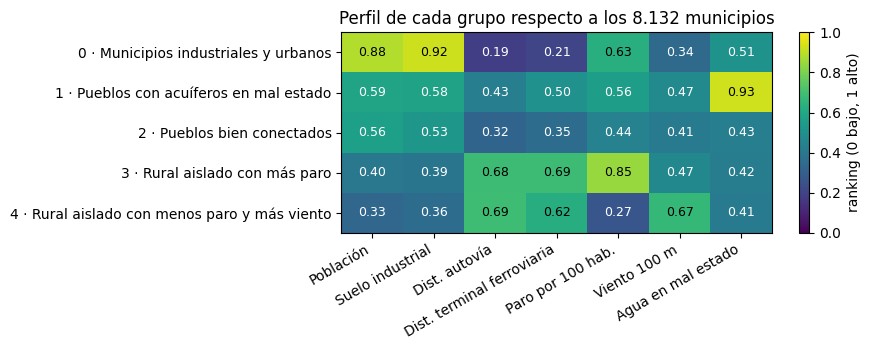

In [6]:
rangos = datos[COLUMNAS].rank(pct=True)
rangos['cluster'] = datos['cluster']
mapa = rangos.groupby('cluster')[COLUMNAS].mean()

etiquetas_var = ['Población', 'Suelo industrial', 'Dist. autovía', 'Dist. terminal ferroviaria',
                 'Paro por 100 hab.', 'Viento 100 m', 'Agua en mal estado']
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(mapa.to_numpy(), cmap='viridis', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(COLUMNAS)), etiquetas_var, rotation=30, ha='right')
ax.set_yticks(range(5), [f'{i} · {PERFILES[i]["nombre"]}' for i in range(5)])
for i in range(5):
    for j in range(len(COLUMNAS)):
        v = mapa.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if v < 0.6 else 'black', fontsize=9)
fig.colorbar(im, ax=ax, label='ranking (0 bajo, 1 alto)')
ax.set_title('Perfil de cada grupo respecto a los 8.132 municipios')
plt.tight_layout()
plt.show()

## 5. Nombres de los perfiles

Los nombres salen de lo que más distingue a cada grupo en las tablas de arriba. Están en `src/sitewise/ml/perfiles.py`; si el equipo prefiere otros nombres, se cambian ahí.

| Grupo | Perfil | Qué lo distingue |
|---|---|---|
| 0 | Municipios industriales y urbanos | Los más grandes (desde pueblos grandes hasta las mayores ciudades), casi todos con suelo industrial y muy cerca de autovía y tren de mercancías |
| 1 | Pueblos con acuíferos en mal estado | Unos 1.000 habitantes; su agua subterránea está casi toda en mal estado cuantitativo |
| 2 | Pueblos bien conectados | Unos 900 habitantes, cerca de autovía, paro por debajo de la mediana |
| 3 | Rural aislado con más paro | Pequeños, lejos de autovía y tren, sin suelo industrial, el paro más alto |
| 4 | Rural aislado con menos paro y más viento | Los más pequeños, lejos de todo, el paro más bajo y el viento más alto |

In [7]:
datos['cluster_perfil'] = datos['cluster'].map(lambda c: PERFILES[c]['nombre'])
print(datos.groupby(['cluster', 'cluster_perfil']).size().rename('municipios').to_string())

cluster  cluster_perfil                           
0        Municipios industriales y urbanos             892
1        Pueblos con acuíferos en mal estado          1107
2        Pueblos bien conectados                      2145
3        Rural aislado con más paro                   1504
4        Rural aislado con menos paro y más viento    2484


## 6. Cosas que hay que saber antes de usar los perfiles

1. **Los grupos son exploratorios.** Los municipios forman un continuo, no islas separadas (Silhouette bajo, ver arriba). Los perfiles ayudan a decir «este municipio se parece a estos otros», no a clasificar con precisión.
2. **El paro de los grupos 3 y 4 depende en parte de cómo se construyó.** En los municipios muy pequeños el SEPE oculta el dato (menos de 5 parados) y se usó 2,5 parados para entrenar, así que su tasa depende de la población por construcción. La tabla siguiente muestra cuántos municipios de cada grupo están en ese caso.
3. **El grupo 1 está definido sobre todo por el agua.** Sin esa variable los grupos cambian mucho (notebook 08). Además, 722 municipios no tienen masa de agua catalogada y su valor es una estimación con los vecinos más cercanos (se muestra como `aproximado` en la app).
4. **El perfil describe el territorio, no el riesgo.** El riesgo y el atractivo se calculan aparte, en la puntuación de cada actividad.

In [8]:
origen_paro = pd.crosstab(datos['cluster'], datos['paro_origen'], normalize='index').round(2)
origen_agua = pd.crosstab(datos['cluster'], datos['agua_origen'], normalize='index').round(2)
print('Origen del dato de paro (proporción de municipios de cada grupo):')
print(origen_paro.to_string())
print()
print('Origen del dato de agua (proporción):')
print(origen_agua.to_string())

Origen del dato de paro (proporción de municipios de cada grupo):
paro_origen  blanco_fuente  ocultado_menor5  publicado
cluster                                               
0                     0.00             0.00       1.00
1                     0.01             0.12       0.87
2                     0.01             0.11       0.88
3                     0.04             0.18       0.78
4                     0.07             0.38       0.55

Origen del dato de agua (proporción):
agua_origen  estimado_vecinos  observado
cluster                                 
0                        0.02       0.98
1                        0.02       0.98
2                        0.08       0.92
3                        0.18       0.82
4                        0.09       0.91


## 7. Municipios atípicos

DBSCAN (notebook 06) marca como ruido los municipios que no encajan en ningún grupo denso, sobre todo ciudades muy grandes. Se guarda como una columna aparte, `es_atipico`, para que la app pueda avisar de que su perfil es menos representativo. Ojo: esa marca viene de la primera prueba (4 variables), no de las 7.

In [9]:
dbscan = pd.read_csv(ML / 'clusters_dbscan_v01.csv', dtype={'cod_ine': str})
datos = datos.merge(dbscan, on='cod_ine', how='left', validate='one_to_one')
assert datos['grupo_dbscan'].notna().all(), 'Faltan municipios en clusters_dbscan_v01.csv'
datos['es_atipico'] = (datos['grupo_dbscan'] == -1).astype(int)
print('Atípicos:', int(datos['es_atipico'].sum()))
print(pd.crosstab(datos['cluster'], datos['es_atipico']).rename(columns={0: 'normal', 1: 'atípico'}).to_string())

Atípicos: 360
es_atipico  normal  atípico
cluster                    
0              677      215
1             1054       53
2             2075       70
3             1490       14
4             2476        8


## 8. Ficheros de salida

Se guardan en `data/reference/` (se sube a Git, son pequeños):

- `perfiles_municipios_v01.csv`: una fila por municipio, con `cod_ine`, `cluster`, `cluster_perfil`, `es_atipico` y `version_modelo`. Es el que usan Adriana y Josema.
- `perfiles_definicion_v01.csv`: una fila por perfil, con su nombre, descripción, número de municipios y medianas.

In [10]:
SALIDA.mkdir(parents=True, exist_ok=True)
tabla = tabla_perfiles(datos['cod_ine'], datos['cluster'], datos['es_atipico'], VERSION_MODELO)
tabla = tabla.sort_values('cod_ine').reset_index(drop=True)  # orden estable: facilita comparar versiones en Git

assert len(tabla) == 8132 and tabla['cod_ine'].is_unique
assert sorted(tabla['cluster'].unique()) == [0, 1, 2, 3, 4]
assert not tabla.isna().any().any()
tabla.to_csv(SALIDA / 'perfiles_municipios_v01.csv', index=False, encoding='utf-8', lineterminator='\n')

definicion = pd.DataFrame({
    'cluster': range(5),
    'cluster_perfil': [PERFILES[i]['nombre'] for i in range(5)],
    'descripcion': [PERFILES[i]['descripcion'] for i in range(5)],
    'n_municipios': datos.groupby('cluster').size().to_numpy(),
}).join(medianas.round(2).add_prefix('mediana_').reset_index(drop=True))
definicion['version_modelo'] = VERSION_MODELO
definicion.to_csv(SALIDA / 'perfiles_definicion_v01.csv', index=False, encoding='utf-8', lineterminator='\n')

# Comprobación: al releerlos, los códigos siguen siendo texto de 5 dígitos
leido = pd.read_csv(SALIDA / 'perfiles_municipios_v01.csv', dtype={'cod_ine': str})
assert leido['cod_ine'].str.fullmatch(r'\d{5}').all()
print(leido.head(3).to_string(index=False))
print('Guardado en', SALIDA)

cod_ine  cluster                    cluster_perfil  es_atipico version_modelo
  01001        0 Municipios industriales y urbanos           0            v01
  01002        0 Municipios industriales y urbanos           0            v01
  01003        2           Pueblos bien conectados           0            v01
Guardado en /sessions/rcw-014rbfwknp8qhmgiqh5ln7ya/mnt/SiteWise/data/reference


## 9. Mapa de los grupos sobre el PCA

Los dos primeros componentes del PCA, coloreados por perfil. Es solo una vista aproximada: el PCA tiene 5 componentes y aquí se ven 2.

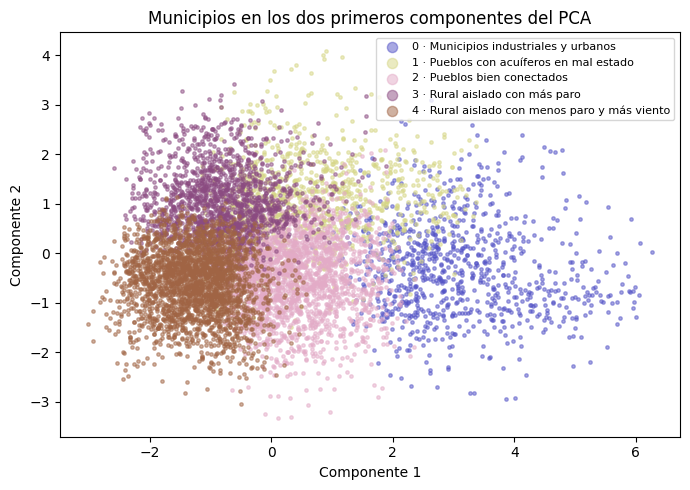

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
colores = ['#5353C6', '#D6D685', '#E3ABC7', '#8B4B81', '#A06444']
for c in range(5):
    m = datos['cluster'].to_numpy() == c
    ax.scatter(espacio[m, 0], espacio[m, 1], s=6, alpha=0.5, color=colores[c], label=f'{c} · {PERFILES[c]["nombre"]}')
ax.set_xlabel('Componente 1')
ax.set_ylabel('Componente 2')
ax.set_title('Municipios en los dos primeros componentes del PCA')
ax.legend(markerscale=3, fontsize=8, loc='best')
plt.tight_layout()
plt.show()

## 10. Qué hemos aprendido

- Con las 7 variables y K=5, el modelo separa **municipios industriales y urbanos**, **pueblos sobre acuíferos en mal estado**, **pueblos bien conectados** y **dos tipos de municipio rural aislado**.
- El fichero `perfiles_municipios_v01.csv` ya tiene el formato acordado para la API y el RAG.
- La ficha del modelo (`docs/methodology/model_card_clustering.md`) recoge qué hace, qué no hace y sus límites.